## 1. Imports

In [3]:
import os, glob
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## 2. Load the data

In [4]:
def find_file(pattern):
    for base in ["/kaggle/input", "."]:
        hits = glob.glob(os.path.join(base, "**", pattern), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(f"No file matching {pattern}")

TRAIN_PATH = find_file("train*.csv")   
TEST_PATH = find_file("test*.csv")      
print("Train:", TRAIN_PATH)
print("Test :", TEST_PATH)

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print(train.shape, test.shape)
train.head()

Train: /kaggle/input/datasets/jefraim/titanic-dataset/train-selected-columns.csv
Test : /kaggle/input/datasets/jefraim/titanic-dataset/test.csv
(891, 10) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500


## 3. Ticket converter 


In [5]:
ticket_counts = pd.concat([train["Ticket"], test["Ticket"]]).value_counts()

def prepare(df):
    X = pd.DataFrame(index=df.index)
    X["Sex"] = (df["Sex"] == "female").astype(int)     
    X["Age"] = df["Age"]
    X["SibSp"] = df["SibSp"]
    X["Parch"] = df["Parch"]
    X["Fare"] = df["Fare"]

    title = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    X["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")

    X["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    X["TicketGroup"] = df["Ticket"].map(ticket_counts)
    X["TicketHasPrefix"] = df["Ticket"].str.contains(r"[A-Za-z]").astype(int)
    return X

X_all = pd.get_dummies(prepare(train), columns=["Title"])
X_final = pd.get_dummies(prepare(test), columns=["Title"])
X_final = X_final.reindex(columns=X_all.columns, fill_value=0)
y = train["Survived"]

for col in ["Age", "Fare"]:
    med = X_all[col].median()
    X_all[col] = X_all[col].fillna(med)
    X_final[col] = X_final[col].fillna(med)

X_all.head()

,Sex,Age,SibSp,Parch,Fare,FamilySize,TicketGroup,TicketHasPrefix,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,22.0,1,0,7.2500,2,1,1,False,False,True,False,False
1,1,38.0,1,0,71.2833,2,2,1,False,False,False,True,False
2,1,26.0,0,0,7.9250,1,1,1,False,True,False,False,False
3,1,35.0,1,0,53.1000,2,2,0,False,False,False,True,False
4,0,35.0,0,0,8.0500,1,1,0,False,False,True,False,False


## 4. Split into training and validation sets


In [6]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y, test_size=0.2, random_state=42, stratify=y
)
print(X_tr.shape, X_val.shape)

(712, 13) (179, 13)


## 5. Training decision tree


In [7]:
model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
model.fit(X_tr, y_tr)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)

## 6. Test the accuracy

In [8]:
pred = model.predict(X_val)
print("Training accuracy  :", round(accuracy_score(y_tr, model.predict(X_tr)), 4))
print("Validation accuracy:", round(accuracy_score(y_val, pred), 4))

cv = cross_val_score(DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42),
                     X_all, y, cv=5)
print("5-fold CV accuracy :", round(cv.mean(), 4), "+/-", round(cv.std(), 4))

print()

Training accuracy  : 0.8371
Validation accuracy: 0.8101
5-fold CV accuracy : 0.8159 +/- 0.0294



## 7. Which features mattered?

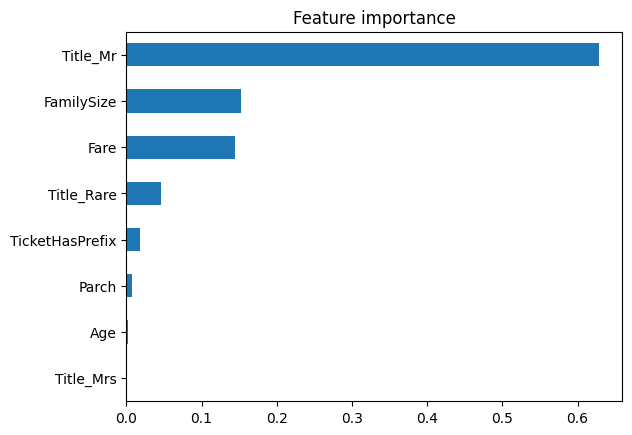

In [9]:
imp = pd.Series(model.feature_importances_, index=X_all.columns).sort_values()
imp.tail(8).plot(kind="barh", title="Feature importance")
plt.show()